In [6]:
from solver.rwg.rwg1 import *
from solver.rwg.rwg2 import *
from solver.rwg.rwg3 import *
from solver.rwg.rwg4 import *
from solver.rwg.rwg5 import *

from solver.utils.file_path import *

from solver.efield.efield1 import *
from solver.efield.efield2 import radiation_intensity_distribution_over_sphere_surface
from solver.efield.efield3 import antenna_directivity_pattern

from solver.utils.frequency_sweep import *

In [7]:
name = "loop4"
path = setup_save_file_paths(name)

In [ ]:
# loop4's mesh predates the gmsh pipeline (translated directly from the
# original Makarov MATLAB mesh -- no .msh file exists for it), so it is
# loaded straight from path.mat instead of going through
# radiation_algorithm()'s extract_msh_to_mat() step. Everything after that
# mirrors radiation_algorithm() exactly.
feed_point = np.array([0.1, 0, 0])
frequency = 4.8e6
voltage_amplitude = 1
# The nearest RWG edges to this feed point run along z (checked directly
# against the mesh), and sit ~0.12-0.13 m away from the exact feed
# coordinate, so gap_width must be opened up past the default 0.05 to
# actually reach them without pulling in unrelated parts of the loop.
excitation_unit_vector = 'y'
gap_width = 0.5

p, t = load_mesh_file(path.mat)

points = Points(p)
triangles = Triangles(t)
triangles.calculate_triangles_area_and_center(points)
edges = triangles.get_edges()
filter_complexes_jonctions(points, triangles, edges)

print(f"Number of points: {points.total_of_points}")
print(f"Number of triangles: {triangles.total_of_triangles}")
print(f"Number of edges: {edges.total_number_of_edges}")

edges.compute_edges_length(points)
DataManager_rwg1.save_data(path, points, triangles, edges)

vecteurs_rho = Vecteurs_Rho()
vecteurs_rho.calculate_vecteurs_rho(points, triangles, edges)
DataManager_rwg2.save_data(path, vecteurs_rho)

omega, mu, epsilon, light_speed_c, eta, matrice_z = calculate_z_matrice(points, triangles, edges, frequency)
DataManager_rwg3.save_data(path, frequency, omega, mu, epsilon, light_speed_c, eta, matrice_z)

frequency, voltage, current, port_results = calculate_current_radiation(path, feed_point, voltage_amplitude, excitation_unit_vector=excitation_unit_vector, gap_width=gap_width)

gap_currents = np.array([p['gap_current'] for p in port_results])
gap_voltages = np.array([p['source_voltage'] for p in port_results])
impedances   = np.array([p['impedance'] for p in port_results])
feed_powers  = np.array([p['power'] for p in port_results])

DataManager_rwg4.save_data_for_radiation(path, frequency, omega, mu, epsilon, light_speed_c, eta,
                                         voltage, current, gap_currents, gap_voltages, impedances, feed_powers)

surface_current_density, surface_current_vector = calculate_current_density(current, triangles, edges, vecteurs_rho)

fig = visualize_surface_current(points, triangles, surface_current_density, feed_point, path.name, current_vector=surface_current_vector)
fig.show()

output_dir_fig_image = "data/fig_image/"
os.makedirs(output_dir_fig_image, exist_ok=True)
antennas_name = path.name + ' antenna surface current in radiation mode'
pdf_path = os.path.join(output_dir_fig_image, antennas_name.replace(" ", "_") + ".pdf")
fig.update_layout(paper_bgcolor='rgba(0,0,0,0)', plot_bgcolor='rgba(0,0,0,0)', margin=dict(l=0, r=0, t=0, b=0))
fig.write_image(pdf_path, format="pdf")
print(f"\nImage saved in PDF format: {pdf_path}\n")


Frequency = 4800000.0 Hz
Wavelength lambda = 62.44840707929359 m
The observation point is : [100   0   0]

e_field_total of loop4 at the observation point [100   0   0] is :
-0.0000012 - 0.0000017i V/m
 0.0001701 + 0.0003519i V/m
 0.0005569 + 0.0004678i V/m

h_field_total of loop4 at the observation point [100   0   0] is :
-0.0000000 - 0.0000000i A/m
-0.0000015 + 0.0000013i A/m
 0.0000004 + 0.0000009i A/m

Poynting vector is equal to : 
9.096863194744922e-10 W/m^2
1.0317793196763384e-12 W/m^2
-1.1489876549879625e-13 W/m^2

w = 9.096869118599754e-10 W/m^2

u = 9.096869118599755e-06 W/unit solid angle
Calculating radiation intensity distribution over sphere surface...
Hollow sphere loaded: 5150 points, 10296 triangles.

[Antenna Results]
  Total Radiated Power : 7.687833160273115e-05 W
  Gain : 1.4881 (1.73 dBi)

[Power Budget]
  P_in  (0.5*Re(V·I*)) = 5.293097e-04 W
  P_rad (sphere integ.) = 7.687833e-05 W
  Raw efficiency       = 14.5243 %
  Port 0: Z_in = 1.8921+42.2344j Ω  |  R_in 

Image saved: data/fig_image/radiation_pattern_loop4.pdf
Generating antenna directivity pattern...
Data loaded from data/antennas_gain_power/loop4_gain_power.mat


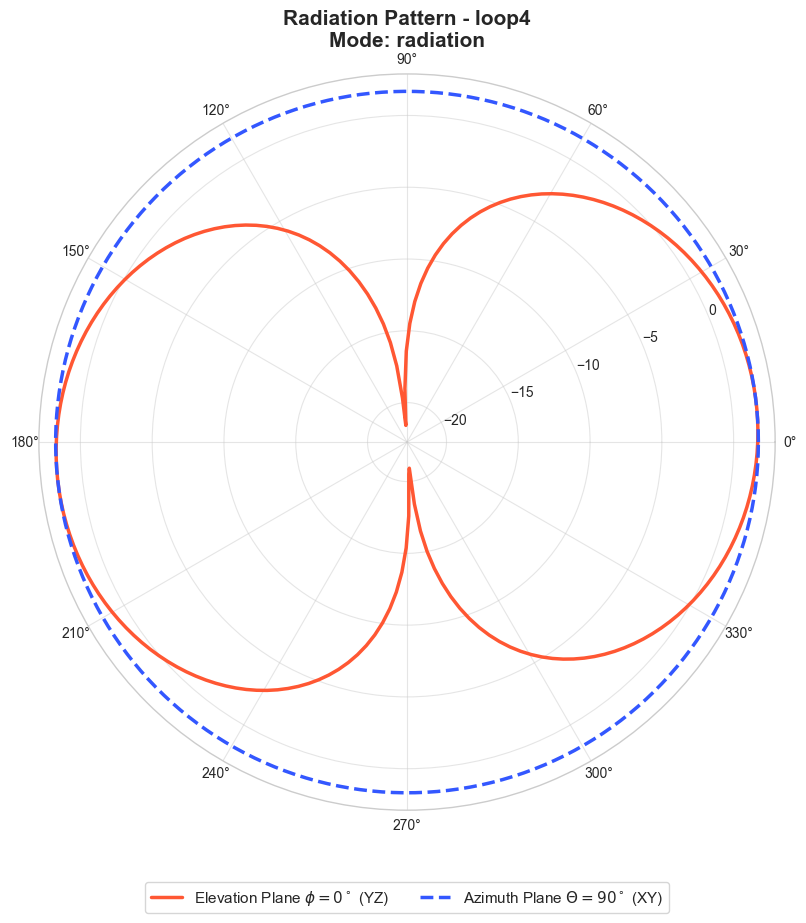

In [9]:
observationPoint = np.array([100, 0, 0])

calculate_electric_magnetic_field_at_point(path, observationPoint)

print("Calculating radiation intensity distribution over sphere surface...")
radiation_intensity_distribution_over_sphere_surface(path, save_image=True)

print("Generating antenna directivity pattern...")
antenna_directivity_pattern(path, mode='radiation', save_image=True)